#### **Librerías necesarias**

In [3]:
import pandas as pd

#### **Importación de archivos y definición de dataframe**

In [4]:
amzn = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [5]:
amzn.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


#### **Part 1: Understanding Product Categories**

##### *Frequency Tables:*

- Generate a frequency table for the product category.

In [6]:
amzn['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

- Which are the top 5 most listed product categories?

In [5]:
amzn_top5 = amzn['category'].value_counts().sort_values(ascending=False).head(5)
amzn_top5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

*Visualizations:*

- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

<Axes: xlabel='category'>

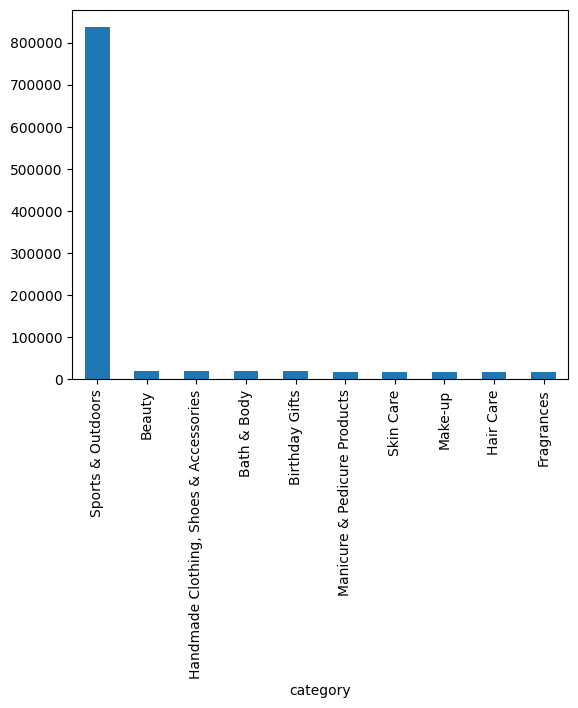

In [7]:
amzn_top10 = amzn['category'].value_counts().sort_values(ascending=False).head(10)

amzn_top10.plot(kind='bar')

- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

<Axes: ylabel='count'>

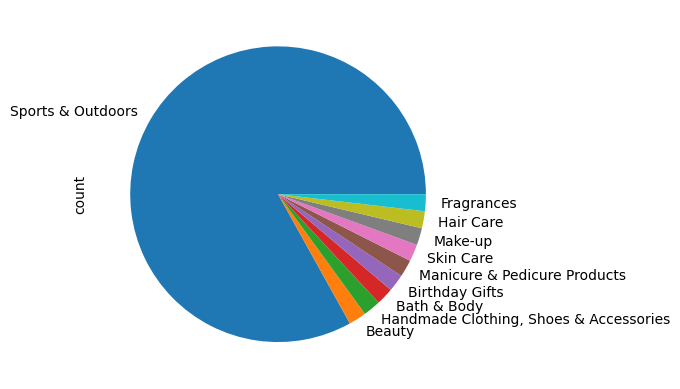

In [8]:
amzn_top10.plot(kind='pie')

**Business Question:** *What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?*



Most of the categories have similar frequencies except Sports and outdoors that dominates over the rest ones.

#### **Part 2: Delving into Product Pricing**

*Measures of Centrality:*

- Calculate the mean, median, and mode for the price of products.

In [14]:
mean_price = amzn['price'].mean()
median_price = amzn['price'].median()
mode_price = amzn['price'].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24380943923661), np.float64(19.09), np.float64(9.99))

- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [12]:
mean_price = amzn['price'].mean()
mode_price = amzn['price'].mode()[0]

mean_price, mode_price

(np.float64(89.24380943923661), np.float64(9.99))

The mean is much higher than the mode, which explain that there are a few products that increase a lot the mean price (outliers). However, the price that is more often is 9.99m which suggests products are typically cheap.

*Measures of Dispersion:*

- Determine the variance, standard deviation, range, and interquartile range for product price.

In [15]:
variance = amzn['price'].var()
std_dev = amzn['price'].std()
price_range = amzn['price'].max() - amzn['price'].min()

q1 = amzn['price'].quantile(0.25)
q3 = amzn['price'].quantile(0.75)
iqr = q3 - q1

variance, std_dev, price_range, iqr

(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(100000.0),
 np.float64(36.0))

- How varied are the product prices? Are there any indicators of a significant spread in prices?

The prices have many outliers or extreme products, but most of the products are fairly concentrated around the median.

*Visualizations:*

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

<Axes: ylabel='Frequency'>

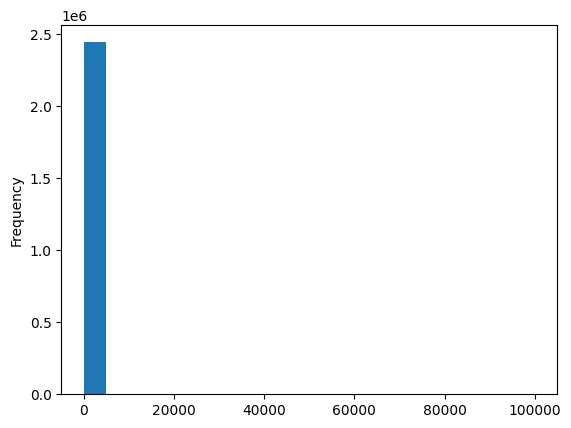

In [22]:
amzn['price'].plot(kind='hist', bins=20)

<Axes: ylabel='Frequency'>

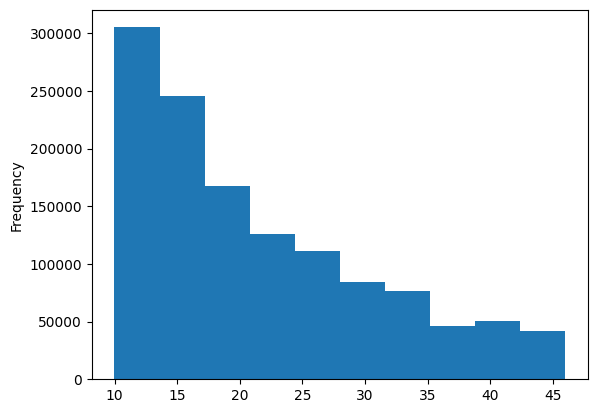

In [21]:
q1 = amzn['price'].quantile(0.25)
q3 = amzn['price'].quantile(0.75)
amzn['price'][(amzn['price'] >= q1) & (amzn['price'] <= q3)].plot(kind='hist', bins=10)

- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

<Axes: >

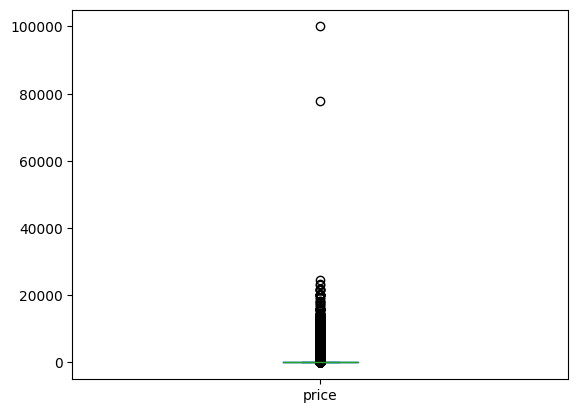

In [ ]:
amzn['price'].plot.box()

<Axes: >

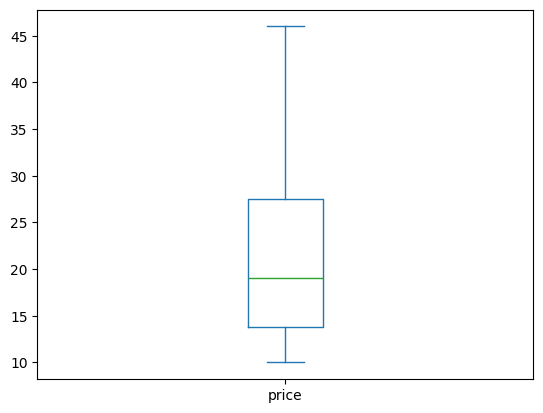

In [24]:
q1 = amzn['price'].quantile(0.25)
q3 = amzn['price'].quantile(0.75)

central_prices = amzn['price'][(amzn['price'] >= q1) & (amzn['price'] <= q3)]

central_prices.plot.box()

**Business Question:** *How are products priced on Amazon UK, and are there specific price points or ranges that are more common?*

Almost all of the products have a price lower than 20000, but there are two outliers that alter all the table distribution.

#### **Part 3: Unpacking Product Ratings**

*Measures of Centrality:*

- Calculate the mean, median, and mode for the rating of products.

In [27]:
mean_rating = amzn['stars'].mean()
median_rating = amzn['stars'].median()
mode_rating = amzn['stars'].mode()[0]

mean_rating, median_rating, mode_rating

(np.float64(2.152836472966066), np.float64(0.0), np.float64(0.0))

- How do customers generally rate products? Is there a common trend?

Most products are rated 0, since both the median and mode are 0.
The mean of 2.15 is higher than 0, which suggests there are some products with higher ratings pulling the average up, but they are few compared to the bulk of products.
Overall, the common trend is that customers mostly do not rate products, and only a small portion have actual ratings.

*Measures of Dispersion:*

- Determine the variance, standard deviation, and interquartile range for product rating.

In [28]:
variance = amzn['stars'].var()
std_dev = amzn['stars'].std()
price_range = amzn['stars'].max() - amzn['stars'].min()

q1 = amzn['stars'].quantile(0.25)
q3 = amzn['stars'].quantile(0.75)
iqr = q3 - q1

variance, std_dev, price_range, iqr

(np.float64(4.817434029796864),
 np.float64(2.194865378513421),
 np.float64(5.0),
 np.float64(4.4))

- Are the ratings consistent, or is there a wide variation in customer feedback?

Most product prices are close to each other. The IQR (4.4) is almost the same as the range (5), and the standard deviation (2.19) is small, showing moderate spread with no extreme outliers.

*Shape of the Distribution:*

- Calculate the skewness and kurtosis for the rating column.

In [29]:
skewness = amzn['stars'].skew()
print("Skewness:", skewness)

Skewness: 0.08120735761080881


In [30]:
kurtosis = amzn['stars'].kurt()
print("Kurtosis:", kurtosis)

Kurtosis: -1.9260061280432994


- Are the ratings normally distributed, or do they lean towards higher or lower values?

Ratings are roughly symmetric (skew ≈ 0) but flatter than normal (kurtosis < 0). Most products have low ratings, with no strong lean toward high or low values.

*Visualizations:*

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: ylabel='Frequency'>

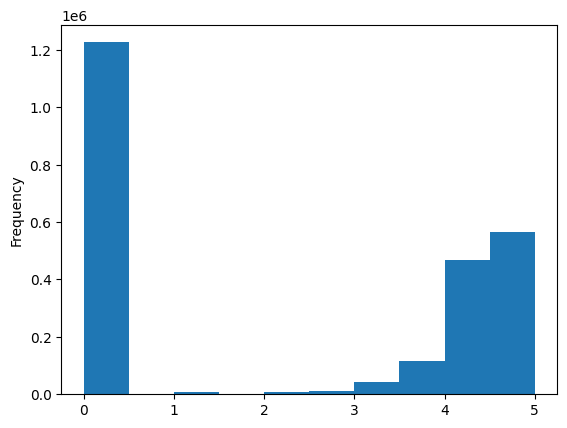

In [33]:
amzn['stars'].plot.hist()

0 stars is the most common rating, which suggests that there are a wide proportion of products that are not being rated.

**Business Question:** *How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?*

The products that have been rated have high rating stars but there is a high proportion of articles not being rated or rated with 0 stars.